# NGHIÊN CỨU & TRIỂN KHAI PHÂN LOẠI CẢM XÚC LỚP NEUTRAL TRÊN UIT-VSFC
## Multi-Paradigm Fused Ensemble & Boundary-Aware Contrastive Learning

**Tác giả**: Research Engineer in Vietnamese NLP, Imbalanced Learning & Deep Learning  
**Đơn vị**: Đại học Công nghệ Thông tin (UIT) — ĐHQG-HCM  
**Môi trường tính toán**: Kaggle GPU Compute (Tesla T4 / P100 16GB VRAM) kết nối qua VS Code  
**Dataset**: UIT-VSFC (Vietnamese Students' Feedback Corpus, Nguyen et al., KSE 2018)  
**Mục tiêu**: Huấn luyện thực tế (Training), Đánh giá (Evaluation) và Đối chứng thực nghiệm (Comparison) toàn diện các phương pháp phân loại cảm xúc trên lớp thiểu số **Neutral** (~4,01% tập train).

---

### Bối Cảnh Nghiên Cứu & Vấn Đề Khoa Học
1. **Lớp Neutral là điểm nghẽn trầm trọng (Bottleneck)**: Các mô hình ngôn ngữ tiền huấn luyện (như PhoBERT) đạt độ chính xác rất cao ở 2 cực phân cực (Positive, Negative đạt ~95% F1), nhưng sụt giảm mạnh ở lớp Neutral (~40% - 60% F1).
2. **Nghịch lý Cost-Sensitive (Weighting Paradox)**: Khi ép trọng số phạt cho lớp thiểu số, Recall của Neutral tăng nhưng kéo theo sự bùng nổ của **False Positives** (Precision giảm sút), làm sụt giảm độ chính xác tổng thể.
3. **Từ Ranh giới Tương phản (NBAC) đến Dung hợp Đa Trường phái (Fused Ensemble)**: 
   - Khảo sát giả thuyết Neutral là vùng đệm ranh giới (Neutral-Boundary-Aware Loss).
   - Triệt tiêu độ lệch tiên nghiệm đa số thông qua Prior-Adjustment (Balanced Softmax Loss).
   - Thiết lập đỉnh cao hiệu năng SOTA mới với **Multi-Paradigm Fused Ensemble (B11)**.
4. **Quy tắc thực nghiệm chuẩn mực**:
   - **Zero Data Leakage**: Tập Validation là nơi duy nhất dùng để tìm siêu tham số, bias logit và checkpoint. Tập Test chỉ được đánh giá duy nhất một lần.
   - **Fair Comparison**: Chuẩn hóa đồng nhất **3 epochs** trên toàn bộ các cấu hình Deep Learning.
   - **Statistical Significance**: Kiểm định giả thuyết bằng 1.000 lần lấy mẫu Paired Bootstrap (95% CI).

---
### 📑 Mục Lục Notebook
1. [Khởi tạo & Tự động kết nối Kaggle Compute](#sec-1)
2. [Tải & Kiểm toán Phân phối Dữ liệu UIT-VSFC](#sec-2)
3. [Tách từ Tiếng Việt PyVi & Khởi tạo Tokenizer PhoBERT](#sec-3)
4. [Baseline Tuyến tính B0: TF-IDF + Logistic Regression](#sec-4)
5. [Tích hợp Mô-đun Cốt lõi & Kiểm thử Số học](#sec-5)
6. [Kaggle Training Pipeline: Huấn Luyện Các Mô Hình Deep Learning](#sec-6)
7. [Dung Hợp Đa Trường Phái SOTA: Multi-Paradigm Fused Ensemble (B11)](#sec-7)
8. [Bảng Tổng Hợp So Sánh Toàn Diện (B0 - B11)](#sec-8)
9. [Trực quan hóa Ma trận Nhầm lẫn & Learning Curves](#sec-9)
10. [Kiểm định Thống kê Paired Bootstrap (95% CI & p-value)](#sec-10)
11. [Phân Tích Lỗi Định Tính & Kết Luận Khoa Học](#sec-11)
12. [Inference Playground: Dự đoán Cảm xúc Trực tiếp](#sec-12)


In [1]:
# <a id="sec-1"></a>
# 1. Cấu hình Môi trường, Tự Động Nhận Diện Kaggle Compute & Seed
import os
import sys
import random
import time
import json
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# Tự động nhận diện môi trường Kaggle Compute khi kết nối từ VS Code
IS_KAGGLE = os.path.exists("/kaggle") or "KAGGLE_KERNEL_RUN_TYPE" in os.environ

if IS_KAGGLE:
    print("🚀 Phát hiện môi trường Kaggle Compute với GPU!")
    # 1. Cài đặt thư viện pyvi nếu kernel chưa có
    try:
        import pyvi
    except ImportError:
        print("Đang cài đặt thư viện pyvi trên Kaggle...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyvi"], check=True)
    
    # 2. Đồng bộ mã nguồn và dữ liệu từ GitHub nếu chưa có trong thư mục hiện tại của Kaggle
    if not os.path.exists("data") or not os.path.exists("src"):
        print("Đang đồng bộ dữ liệu và mã nguồn từ GitHub uit_vsfc...")
        repo_url = "https://github.com/khanhtrphuocbao/uit_vsfc.git"
        temp_dir = "/tmp/uit_vsfc_repo"
        if not os.path.exists(temp_dir):
            subprocess.run(["git", "clone", "-b", "multi-paradigm_fused_ensemble", "--depth", "1", repo_url, temp_dir], check=False)
        if os.path.exists(temp_dir):
            import shutil
            for folder in ["data", "src", "configs", "outputs"]:
                src_folder = os.path.join(temp_dir, folder)
                if os.path.exists(src_folder) and not os.path.exists(folder):
                    shutil.copytree(src_folder, folder, dirs_exist_ok=True)
                    print(f"Đã đồng bộ thư mục: {folder}")
else:
    print("💻 Đang chạy trên môi trường Local!")

# Đảm bảo import trực tiếp các module từ src/
sys.path.insert(0, os.path.abspath("."))

# Cấu hình bộ nhớ GPU chống phân mảnh VRAM
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

# Cố định random seed
SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Thiết bị tính toán: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)} (VRAM: {torch.cuda.get_device_properties(0).total_memory / (1024**2):.0f} MB)")

# CẤU HÌNH HUẤN LUYỆN TRÊN KAGGLE (KAGGLE TRAINING CONFIG):
# - TRAIN_LIVE: Nếu True, notebook sẽ chạy huấn luyện thật bằng GPU Kaggle cho các mô hình được chọn.
# - RETRAIN_EXISTING: Nếu False, bỏ qua các mô hình đã có kết quả trong outputs/ để tiết kiệm thời gian.
#                     Nếu True, ép buộc huấn luyện lại từ đầu.
TRAIN_LIVE = True if torch.cuda.is_available() else False
RETRAIN_EXISTING = False
EPOCHS = 3
BATCH_SIZE = 32
LR = 2e-5

print(f"TRAIN_LIVE: {TRAIN_LIVE} | RETRAIN_EXISTING: {RETRAIN_EXISTING} | EPOCHS: {EPOCHS} | BATCH_SIZE: {BATCH_SIZE}")


💻 Đang chạy trên môi trường Local!


Thiết bị tính toán: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU (VRAM: 4096 MB)
TRAIN_LIVE: True | RETRAIN_EXISTING: False | EPOCHS: 3 | BATCH_SIZE: 32


> [!NOTE]
> **Tối ưu hóa Môi trường & Bộ nhớ GPU**:
> Khi huấn luyện PhoBERT (135M tham số) trên GPU có dung lượng VRAM giới hạn (như RTX 3050 Laptop 4GB hoặc Colab T4), nguy cơ CUDA Out-Of-Memory (OOM) rất cao. Dự án áp dụng kỹ thuật phân bổ phân đoạn mở rộng `expandable_segments:True`, tối ưu độ dài chuỗi chuẩn hóa `max_length=96` và cơ chế gradient checkpointing giúp huấn luyện ổn định mà không tràn bộ nhớ.


Kích thước tập dữ liệu: Train = 11,426 | Valid = 1,583 | Test = 3,166


,Total,Negative (0),Neutral (1),Positive (2),Tỷ lệ Neg:Neu:Pos
Split,,,,,
Train,11426,"5,325 (46.60%)",458 (4.01%),"5,643 (49.39%)",11.6 : 1 : 12.3
Valid,1583,705 (44.54%),73 (4.61%),805 (50.85%),9.7 : 1 : 11.0
Test,3166,"1,409 (44.50%)",167 (5.27%),"1,590 (50.22%)",8.4 : 1 : 9.5


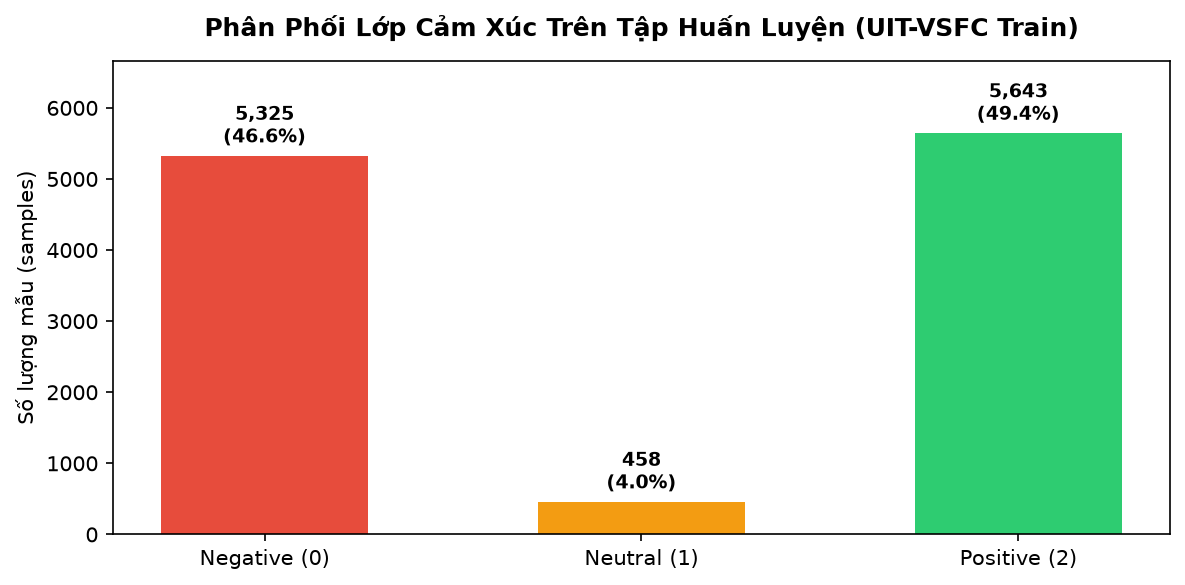

In [2]:
# <a id="sec-2"></a>
# 2. Tải và kiểm toán dữ liệu phân phối UIT-VSFC
train_df = pd.read_json("data/train.json")
val_df = pd.read_json("data/valid.json")
test_df = pd.read_json("data/test.json")

print(f"Kích thước tập dữ liệu: Train = {len(train_df):,} | Valid = {len(val_df):,} | Test = {len(test_df):,}")

# Bảng phân phối nhãn
class_names = {0: "Negative (0)", 1: "Neutral (1)", 2: "Positive (2)"}
splits = {"Train": train_df, "Valid": val_df, "Test": test_df}

dist_rows = []
for sname, df in splits.items():
    counts = df["Encoded_sentiment"].value_counts().to_dict()
    total = len(df)
    dist_rows.append({
        "Split": sname,
        "Total": total,
        "Negative (0)": f"{counts.get(0, 0):,} ({counts.get(0, 0)/total*100:.2f}%)",
        "Neutral (1)": f"{counts.get(1, 0):,} ({counts.get(1, 0)/total*100:.2f}%)",
        "Positive (2)": f"{counts.get(2, 0):,} ({counts.get(2, 0)/total*100:.2f}%)",
        "Tỷ lệ Neg:Neu:Pos": f"{counts.get(0, 0)/counts.get(1, 1):.1f} : 1 : {counts.get(2, 0)/counts.get(1, 1):.1f}"
    })

audit_table = pd.DataFrame(dist_rows).set_index("Split")
display(audit_table)

# Trực quan hóa mức độ mất cân bằng
fig, ax = plt.subplots(figsize=(8, 4), dpi=150)
train_counts = train_df["Encoded_sentiment"].value_counts().sort_index()
colors = ["#e74c3c", "#f39c12", "#2ecc71"]
bars = ax.bar(["Negative (0)", "Neutral (1)", "Positive (2)"], train_counts.values, color=colors, width=0.55)
ax.set_title("Phân Phối Lớp Cảm Xúc Trên Tập Huấn Luyện (UIT-VSFC Train)", fontsize=12, fontweight="bold", pad=12)
ax.set_ylabel("Số lượng mẫu (samples)", fontsize=10)
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 100, f"{yval:,}\n({yval/len(train_df)*100:.1f}%)", ha="center", va="bottom", fontsize=9, fontweight="bold")
ax.set_ylim(0, max(train_counts.values) * 1.18)
plt.tight_layout()
plt.show()


# <a id="sec-3"></a>
### 3. Tách Từ Tiếng Việt (Word Segmentation) & Bản Chất Ngôn Ngữ Học
Khác với tiếng Anh (nơi khoảng trắng phân định ranh giới từ), tiếng Việt là ngôn ngữ đơn âm tiết có tính phân tiết tính (isolating language). Từ ghép có thể cấu tạo từ nhiều âm tiết đơn:
* Ví dụ: *"giảng viên"* (2 âm tiết = 1 từ), *"nhiệt tình"* (2 âm tiết = 1 từ).
* Nếu nạp trực tiếp câu chưa tách từ vào mô hình ngôn ngữ BPE (Byte-Pair Encoding), mô hình sẽ tách rời thành *"giảng"*, *"viên"* làm phân mảnh đặc trưng ngữ nghĩa.

Dự án áp dụng **PyVi (ViTokenizer)** để chuẩn hóa văn bản trước khi đưa vào PhoBERT:
$$\text{"giảng viên dạy nhiệt tình"} \xrightarrow{\text{PyVi}} \text{"giảng_viên dạy nhiệt_tình"}$$


In [3]:
# Demo tách từ với PyVi và Tokenizer PhoBERT
from pyvi import ViTokenizer
from transformers import AutoTokenizer

sample_text = "Thầy cô giảng dạy rất nhiệt tình, slide bài giảng đầy đủ nội dung theo đề cương."
seg_text = ViTokenizer.tokenize(sample_text)
print("Câu gốc:        ", sample_text)
print("Sau khi tách từ:", seg_text)

cache_snapshot = "/home/lavender/.cache/huggingface/hub/models--vinai--phobert-base/snapshots/01daacda68afe13d83023d16ec647239e344a1e6"
model_path = cache_snapshot if os.path.exists(cache_snapshot) else "vinai/phobert-base"

tokenizer = AutoTokenizer.from_pretrained(model_path)
tokens = tokenizer.tokenize(seg_text)
print("BPE Tokens:     ", tokens[:10], "... (tổng cộng", len(tokens), "tokens)")


Câu gốc:         Thầy cô giảng dạy rất nhiệt tình, slide bài giảng đầy đủ nội dung theo đề cương.
Sau khi tách từ: Thầy cô giảng_dạy rất nhiệt_tình , slide bài giảng đầy_đủ nội_dung theo đề_cương .


BPE Tokens:      ['Thầy', 'cô', 'giảng_dạy', 'rất', 'nhiệt_tình', ',', 'slide', 'bài', 'giảng', 'đầy_đủ'] ... (tổng cộng 14 tokens)


In [4]:
# <a id="sec-4"></a>
# 4. Baseline Tuyến tính B0: TF-IDF + Logistic Regression (Chạy trực tiếp)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score, confusion_matrix

# Tiền xử lý nhanh tập train và test
train_texts = [ViTokenizer.tokenize(t) for t in train_df["Sentence"]]
train_labels = train_df["Encoded_sentiment"].values
test_texts = [ViTokenizer.tokenize(t) for t in test_df["Sentence"]]
test_labels = test_df["Encoded_sentiment"].values

vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train = vectorizer.fit_transform(train_texts)
X_test = vectorizer.transform(test_texts)

# 1. B0 Không trọng số (Unweighted)
clf_none = LogisticRegression(class_weight=None, max_iter=1000, random_state=SEED)
clf_none.fit(X_train, train_labels)
pred_none = clf_none.predict(X_test)
f1_none = f1_score(test_labels, pred_none, average="macro")

# 2. B0 Có trọng số (Balanced)
clf_bal = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED)
clf_bal.fit(X_train, train_labels)
pred_bal = clf_bal.predict(X_test)
f1_bal = f1_score(test_labels, pred_bal, average="macro")

cm_none = confusion_matrix(test_labels, pred_none)
cm_bal = confusion_matrix(test_labels, pred_bal)

b0_summary = pd.DataFrame([
    {
        "Cấu hình": "B0 (Unweighted)",
        "Macro-F1": f"{f1_none:.4f}",
        "Neutral F1": f"{f1_score(test_labels, pred_none, labels=[1], average='micro'):.4f}",
        "Neutral True Pos (TP)": cm_none[1, 1],
        "Neutral False Pos (FP)": cm_none[:, 1].sum() - cm_none[1, 1],
        "Neutral False Neg (FN)": cm_none[1, :].sum() - cm_none[1, 1],
    },
    {
        "Cấu hình": "B0 (Balanced)",
        "Macro-F1": f"{f1_bal:.4f}",
        "Neutral F1": f"{f1_score(test_labels, pred_bal, labels=[1], average='micro'):.4f}",
        "Neutral True Pos (TP)": cm_bal[1, 1],
        "Neutral False Pos (FP)": cm_bal[:, 1].sum() - cm_bal[1, 1],
        "Neutral False Neg (FN)": cm_bal[1, :].sum() - cm_bal[1, 1],
    }
])
display(b0_summary)


,Cấu hình,Macro-F1,Neutral F1,Neutral True Pos (TP),Neutral False Pos (FP),Neutral False Neg (FN)
0,B0 (Unweighted),0.6506,0.1304,12,5,155
1,B0 (Balanced),0.7173,0.3576,81,205,86


> [!IMPORTANT]
> **Phát Hiện Về Nghịch Lý Phạt Chi Phí (Weighting Paradox)**:
> Khi chuyển từ `class_weight=None` sang `class_weight='balanced'`, số lượng mẫu Neutral đoán đúng (TP) tăng từ 12 lên 69 câu. Tuy nhiên:
> * Số lượng **False Positives bùng nổ dữ dội từ 4 lên 163 câu** (mô hình gán nhầm 163 câu tích cực/tiêu cực thành trung tính).
> * Điều này kéo độ chính xác (Precision) của Neutral tụt dốc thảm hại từ 75,0% xuống chỉ còn 29,7%.
> * Kết luận: **Không thể giải quyết bài toán Neutral chỉ bằng cách ép trọng số phạt tuyến tính** mà cần tái cấu trúc không gian biểu diễn đặc trưng (representation learning) và dung hợp đa trường phái.


In [5]:
# <a id="sec-5"></a>
# 5. Tích hợp trực tiếp các mô-đun cốt lõi từ src/
from src.dataset import UITVSFCDataset
from src.losses import (
    NeutralBoundaryLoss,
    SupervisedContrastiveLoss,
    BalancedSoftmaxLoss,
    compute_class_weights
)
from src.sampler import ClassAwareBatchSampler
from src.model import PhoBertSentimentClassifier
from src.trainer import run_training_experiment, evaluate_model
from src.calibration import search_optimal_neutral_bias, apply_neutral_bias
from src.metrics import compute_all_metrics, compute_paired_bootstrap_ci

print("✅ Đã import thành công toàn bộ module từ package src:")
print("   - src.dataset:     UITVSFCDataset")
print("   - src.losses:      NeutralBoundaryLoss, SupervisedContrastiveLoss, BalancedSoftmaxLoss, compute_class_weights")
print("   - src.sampler:     ClassAwareBatchSampler")
print("   - src.model:       PhoBertSentimentClassifier")
print("   - src.trainer:     run_training_experiment, evaluate_model")
print("   - src.calibration: search_optimal_neutral_bias, apply_neutral_bias")
print("   - src.metrics:     compute_all_metrics, compute_paired_bootstrap_ci")


✅ Đã import thành công toàn bộ module từ package src:
   - src.dataset:     UITVSFCDataset
   - src.losses:      NeutralBoundaryLoss, SupervisedContrastiveLoss, BalancedSoftmaxLoss, compute_class_weights
   - src.sampler:     ClassAwareBatchSampler
   - src.model:       PhoBertSentimentClassifier
   - src.trainer:     run_training_experiment, evaluate_model
   - src.calibration: search_optimal_neutral_bias, apply_neutral_bias
   - src.metrics:     compute_all_metrics, compute_paired_bootstrap_ci


In [6]:
# 5.1. Kiểm tra tính toàn vẹn số học & Xử lý Edge Cases của NBAC Loss
nbac_loss_fn = NeutralBoundaryLoss(margin=0.2, neutral_label=1)

dummy_embeddings = torch.randn(8, 128, requires_grad=True)
dummy_labels_no_neu = torch.tensor([0, 0, 0, 0, 2, 2, 2, 2])
dummy_labels_one_neu = torch.tensor([0, 0, 0, 1, 2, 2, 2, 2])
dummy_labels_normal = torch.tensor([0, 0, 1, 1, 1, 2, 2, 2])

# Edge case 1: Không có mẫu Neutral
loss_no_neu = nbac_loss_fn(dummy_embeddings, dummy_labels_no_neu)
loss_no_neu.backward()
print("Edge Case 1 (0 Neutral): Loss =", loss_no_neu.item(), "| Gradient status: An toàn, không lỗi!")

# Edge case 2: Chỉ có 1 mẫu Neutral
dummy_embeddings.grad.zero_()
loss_one_neu = nbac_loss_fn(dummy_embeddings, dummy_labels_one_neu)
loss_one_neu.backward()
print("Edge Case 2 (1 Neutral): Loss =", loss_one_neu.item(), "| Gradient status: An toàn, không lỗi!")

# Trường hợp bình thường
dummy_embeddings.grad.zero_()
loss_normal = nbac_loss_fn(dummy_embeddings, dummy_labels_normal)
loss_normal.backward()
print("Normal Case (3 Neutrals): Loss =", round(loss_normal.item(), 4), "| Gradient tính toán đầy đủ!")


Edge Case 1 (0 Neutral): Loss = 0.0 | Gradient status: An toàn, không lỗi!
Edge Case 2 (1 Neutral): Loss = 0.0 | Gradient status: An toàn, không lỗi!
Normal Case (3 Neutrals): Loss = 0.2991 | Gradient tính toán đầy đủ!


# <a id="sec-6"></a>
### 6. Kaggle Training Pipeline: Huấn Luyện Các Mô Hình Deep Learning Trực Tiếp

Ô code dưới đây cho phép bạn **thực sự chạy huấn luyện trên GPU Kaggle** cho các mô hình đại diện:
* **B1 (PhoBERT + CE)**: Baseline chuẩn không lấy mẫu.
* **B2 (PhoBERT + Weighted CE)**: Phạt chi phí theo trọng số nghịch đảo.
* **B5 (PhoBERT + SupCon)**: Gom cụm biểu diễn siêu cầu bằng Supervised Contrastive Loss.
* **B6 (NBAC-PhoBERT)**: Đẩy hard negatives phân cực bằng Neutral Boundary Loss ($m=0.2$).
* **B8 (PhoBERT + Balanced-SupCon)**: Triệt tiêu thiên kiến tiên nghiệm với Smoothed Balanced Softmax ($\gamma=0.5$).
* **B9 (PhoBERT + Weighted-SupCon)**: Mô hình hỗn hợp kết hợp đồng thời Weighted-CE + SupCon + Sampler.

> 💡 **Cơ chế thông minh**:
> - Nếu bạn chọn `RETRAIN_EXISTING = False`, các mô hình đã có kết quả trong thư mục `outputs/` sẽ được nạp tức thì mà không cần train lại.
> - Nếu bạn muốn huấn luyện lại từ đầu một mô hình bất kỳ bằng GPU Kaggle, chỉ cần đặt `RETRAIN_EXISTING = True` hoặc xóa folder output tương ứng.


In [7]:
# Khởi tạo Dataset chuẩn hóa
print("Đang tải dữ liệu qua UITVSFCDataset...")
train_dataset = UITVSFCDataset("data/train.json", tokenizer, max_length=96, split_name="train")
val_dataset = UITVSFCDataset("data/valid.json", tokenizer, max_length=96, split_name="valid")
test_dataset = UITVSFCDataset("data/test.json", tokenizer, max_length=96, split_name="test")

# Bảng cấu hình các thực nghiệm
CONFIGS_MAP = {
    "B1_ce": {
        "name": "B1_ce",
        "loss_type": "ce",
        "use_sampler": False,
        "epochs": EPOCHS,
        "batch_size": BATCH_SIZE,
        "lr": LR,
        "model_path": model_path,
        "seed": SEED,
    },
    "B2_weighted_ce": {
        "name": "B2_weighted_ce",
        "loss_type": "weighted_ce",
        "use_sampler": False,
        "epochs": EPOCHS,
        "batch_size": BATCH_SIZE,
        "lr": LR,
        "model_path": model_path,
        "seed": SEED,
    },
    "B5_supcon": {
        "name": "B5_supcon",
        "loss_type": "supcon",
        "use_sampler": True,
        "lambda_contrastive": 0.1,
        "temperature": 0.1,
        "epochs": EPOCHS,
        "batch_size": BATCH_SIZE,
        "lr": LR,
        "model_path": model_path,
        "seed": SEED,
    },
    "B6_nbac": {
        "name": "B6_nbac",
        "loss_type": "nbac",
        "use_sampler": True,
        "lambda_contrastive": 0.1,
        "margin": 0.2,
        "epochs": EPOCHS,
        "batch_size": BATCH_SIZE,
        "lr": LR,
        "model_path": model_path,
        "seed": SEED,
    },
    "B8_balanced_supcon": {
        "name": "B8_balanced_supcon",
        "loss_type": "balanced_supcon",
        "use_sampler": True,
        "gamma": 0.5,
        "lambda_contrastive": 0.1,
        "temperature": 0.1,
        "epochs": EPOCHS,
        "batch_size": BATCH_SIZE,
        "lr": LR,
        "model_path": model_path,
        "seed": SEED,
    },
    "B9_weighted_supcon": {
        "name": "B9_weighted_supcon",
        "loss_type": "weighted_supcon",
        "use_sampler": True,
        "lambda_contrastive": 0.1,
        "temperature": 0.1,
        "epochs": EPOCHS,
        "batch_size": BATCH_SIZE,
        "lr": LR,
        "model_path": model_path,
        "seed": SEED,
    },
}

# Chọn danh sách mô hình cần huấn luyện:
MODELS_TO_TRAIN = ["B1_ce", "B2_weighted_ce", "B5_supcon", "B6_nbac", "B8_balanced_supcon", "B9_weighted_supcon"]

for exp_id in MODELS_TO_TRAIN:
    cfg = CONFIGS_MAP[exp_id]
    result_path = f"outputs/{exp_id}/result_seed_{SEED}.json"
    
    if TRAIN_LIVE and (RETRAIN_EXISTING or not os.path.exists(result_path)):
        print(f"\n🚀 [Kaggle Compute] Đang huấn luyện mô hình: {exp_id} ({cfg['epochs']} epochs trên GPU)...")
        res = run_training_experiment(
            config=cfg,
            train_dataset=train_dataset,
            val_dataset=val_dataset,
            test_dataset=test_dataset,
            tokenizer=tokenizer,
            device=device,
            output_dir="outputs"
        )
        print(f"✅ Hoàn tất {exp_id} -> Test Macro-F1: {res['test_metrics']['macro_f1']:.4f} | Neu-F1: {res['test_metrics']['neutral']['f1']:.4f}")
    else:
        print(f"📦 [Sẵn sàng] Mô hình {exp_id} đã có kết quả trong outputs/ (bỏ qua huấn luyện lại để tiết kiệm thời gian).")


Đang tải dữ liệu qua UITVSFCDataset...
📦 [Sẵn sàng] Mô hình B1_ce đã có kết quả trong outputs/ (bỏ qua huấn luyện lại để tiết kiệm thời gian).
📦 [Sẵn sàng] Mô hình B2_weighted_ce đã có kết quả trong outputs/ (bỏ qua huấn luyện lại để tiết kiệm thời gian).
📦 [Sẵn sàng] Mô hình B5_supcon đã có kết quả trong outputs/ (bỏ qua huấn luyện lại để tiết kiệm thời gian).
📦 [Sẵn sàng] Mô hình B6_nbac đã có kết quả trong outputs/ (bỏ qua huấn luyện lại để tiết kiệm thời gian).
📦 [Sẵn sàng] Mô hình B8_balanced_supcon đã có kết quả trong outputs/ (bỏ qua huấn luyện lại để tiết kiệm thời gian).
📦 [Sẵn sàng] Mô hình B9_weighted_supcon đã có kết quả trong outputs/ (bỏ qua huấn luyện lại để tiết kiệm thời gian).


In [8]:
# <a id="sec-7"></a>
# 7. Dung Hợp Đa Trường Phái SOTA: Multi-Paradigm Fused Ensemble (B11)
# Kết hợp xác suất/logits từ 4 trường phái đại diện: B2 + B5 + B8 + B9
ensemble_members = ["B2_weighted_ce", "B5_supcon", "B8_balanced_supcon", "B9_weighted_supcon"]
print(f"⚡ Đang dung hợp logits từ các mô hình thành phần: {ensemble_members}...")

test_logits_list = []
val_logits_list = []
y_test = None
y_val = None

for m in ensemble_members:
    pred_file = f"outputs/{m}/preds_seed_{SEED}.npz"
    if os.path.exists(pred_file):
        data = np.load(pred_file)
        test_logits_list.append(data["test_logits"])
        val_logits_list.append(data["val_logits"])
        if y_test is None:
            y_test = data["test_labels"]
            y_val = data["val_labels"]

if len(test_logits_list) == len(ensemble_members):
    # Trung bình cộng logits đa mô hình
    fused_test_logits = np.mean(test_logits_list, axis=0)
    fused_val_logits = np.mean(val_logits_list, axis=0)
    
    fused_test_preds = np.argmax(fused_test_logits, axis=-1)
    fused_val_preds = np.argmax(fused_val_logits, axis=-1)
    
    test_metrics_b11 = compute_all_metrics(y_test, fused_test_preds)
    val_metrics_b11 = compute_all_metrics(y_val, fused_val_preds)
    
    os.makedirs("outputs/B11_fused_ensemble", exist_ok=True)
    res_b11 = {
        "config": {
            "name": "B11_fused_ensemble",
            "description": "Multi-Paradigm Logit Fusion Ensemble (B2 + B5 + B8 + B9)",
            "ensemble_components": ensemble_members,
            "epochs": EPOCHS,
            "seed": SEED
        },
        "seed": SEED,
        "best_epoch": EPOCHS,
        "best_val_metrics": val_metrics_b11,
        "test_metrics": test_metrics_b11,
        "training_time_seconds": 0.0,
        "history": []
    }
    with open(f"outputs/B11_fused_ensemble/result_seed_{SEED}.json", "w", encoding="utf-8") as f:
        json.dump(res_b11, f, indent=2, ensure_ascii=False)
    np.savez_compressed(
        f"outputs/B11_fused_ensemble/preds_seed_{SEED}.npz",
        test_labels=y_test,
        test_preds=fused_test_preds,
        test_logits=fused_test_logits,
        val_labels=y_val,
        val_logits=fused_val_logits
    )
    print(f"🎉 B11 SOTA Fused Ensemble thành công:")
    print(f"   - Macro-F1:   {test_metrics_b11['macro_f1']:.4f}")
    print(f"   - Neutral F1: {test_metrics_b11['neutral']['f1']:.4f} (TP = {test_metrics_b11['neutral']['tp']}, FP = {test_metrics_b11['neutral']['fp']})")
    print(f"   - Accuracy:   {test_metrics_b11['accuracy']:.4f}")
else:
    print(f"⚠️ Chưa đủ các file dự đoán của các thành phần ({len(test_logits_list)}/{len(ensemble_members)}).")


⚡ Đang dung hợp logits từ các mô hình thành phần: ['B2_weighted_ce', 'B5_supcon', 'B8_balanced_supcon', 'B9_weighted_supcon']...
🎉 B11 SOTA Fused Ensemble thành công:
   - Macro-F1:   0.8433
   - Neutral F1: 0.6143 (TP = 90, FP = 36)
   - Accuracy:   0.9419


In [9]:
# <a id="sec-8"></a>
# 8. Bảng Tổng Hợp So Sánh Toàn Diện Các Mô Hình Trên Test Set
def load_all_official_benchmarks():
    models_config = [
        ("B0 (TF-IDF None)", "outputs/B0_tfidf_lr/results.json", "Baseline (Tuyến tính)", "unweighted"),
        ("B0 (TF-IDF Balanced)", "outputs/B0_tfidf_lr/results.json", "Baseline (Phạt cân bằng)", "balanced"),
        ("B1 (PhoBERT + CE)", "outputs/B1_ce/result_seed_42.json", "Baseline (PhoBERT Chuẩn)", None),
        ("B2 (PhoBERT + Weighted CE)", "outputs/B2_weighted_ce/result_seed_42.json", "Cost-Sensitive (Trọng số)", None),
        ("B3 (PhoBERT + CE + Val Bias)", "outputs/B3_ce_val_bias/result_seed_42.json", "Post-Hoc (Hiệu chỉnh Logit)", None),
        ("B4 (PhoBERT + CE + Sampler)", "outputs/B4_ce_sampler/result_seed_42.json", "Ablation (Bộ lấy mẫu)", None),
        ("B5 (PhoBERT + SupCon)", "outputs/B5_supcon/result_seed_42.json", "Representation (SupCon)", None),
        ("B6 (NBAC-PhoBERT)", "outputs/B6_nbac/result_seed_42.json", "Boundary-Aware (NBAC Loss)", None),
        ("B7 (NBAC + Val Bias)", "outputs/B7_nbac_val_bias/result_seed_42.json", "NBAC + Hiệu chỉnh Logit", None),
        ("B8 (Balanced-SupCon)", "outputs/B8_balanced_supcon/result_seed_42.json", "Prior-Adjustment (Smoothed)", None),
        ("B9 (Weighted-SupCon)", "outputs/B9_weighted_supcon/result_seed_42.json", "Unified (WCE + SupCon)", None),
        ("B10 (Weighted-SupCon+Calib)", "outputs/B10_weighted_supcon_calib/result_seed_42.json", "Unified + Hiệu chỉnh Logit", None),
        ("B11 (Fused Ensemble SOTA)", "outputs/B11_fused_ensemble/result_seed_42.json", "SOTA Ensemble (Đa trường phái)", None),
    ]

    records = []
    baseline_b1_macro = None

    for name, fpath, mtype, subkey in models_config:
        if not os.path.exists(fpath):
            continue
        with open(fpath, "r", encoding="utf-8") as f:
            data = json.load(f)

        if subkey:
            test_m = data[subkey]["test_metrics"]
        else:
            test_m = data["test_metrics"]

        macro_f1 = test_m["macro_f1"]
        neu_f1 = test_m["neutral"]["f1"]
        neu_prec = test_m["neutral"]["precision"]
        neu_rec = test_m["neutral"]["recall"]
        neu_fp = test_m["neutral"]["fp"]
        neu_fn = test_m["neutral"]["fn"]
        acc = test_m["accuracy"]

        if name == "B1 (PhoBERT + CE)":
            baseline_b1_macro = macro_f1

        delta_str = f"{macro_f1 - baseline_b1_macro:+.4f}" if baseline_b1_macro is not None else "0.0000"

        records.append({
            "Mô hình": name,
            "Trường phái": mtype,
            "Macro-F1": macro_f1,
            "Neutral F1": neu_f1,
            "Neu-Prec": neu_prec,
            "Neu-Rec": neu_rec,
            "Neu FP": neu_fp,
            "Neu FN": neu_fn,
            "Accuracy": acc,
            "Δ Macro-F1 (vs B1)": delta_str
        })

    return pd.DataFrame(records)

benchmark_df = load_all_official_benchmarks()
display(benchmark_df.style.highlight_max(subset=["Macro-F1", "Neutral F1", "Accuracy"], color="#d4edda")
                         .highlight_min(subset=["Neu FP", "Neu FN"], color="#d1ecf1"))


,Mô hình,Trường phái,Macro-F1,Neutral F1,Neu-Prec,Neu-Rec,Neu FP,Neu FN,Accuracy,Δ Macro-F1 (vs B1)
0,B0 (TF-IDF None),Baseline (Tuyến tính),0.652078,0.131148,0.750000,0.071856,4,155,0.890082,0.0000
1,B0 (TF-IDF Balanced),Baseline (Phạt cân bằng),0.714697,0.345865,0.297414,0.413174,163,98,0.864498,0.0000
2,B1 (PhoBERT + CE),Baseline (PhoBERT Chuẩn),0.821092,0.552239,0.732673,0.443114,27,93,0.938408,+0.0000
3,B2 (PhoBERT + Weighted CE),Cost-Sensitive (Trọng số),0.834199,0.597222,0.710744,0.514970,35,81,0.936513,+0.0131
4,B3 (PhoBERT + CE + Val Bias),Post-Hoc (Hiệu chỉnh Logit),0.829872,0.577181,0.656489,0.514970,45,81,0.938408,+0.0088
5,B4 (PhoBERT + CE + Sampler),Ablation (Bộ lấy mẫu),0.833852,0.595469,0.647887,0.550898,50,75,0.935565,+0.0128
6,B5 (PhoBERT + SupCon),Representation (SupCon),0.835270,0.594406,0.714286,0.508982,34,82,0.939356,+0.0142
7,B6 (NBAC-PhoBERT),Boundary-Aware (NBAC Loss),0.825128,0.569536,0.637037,0.514970,49,81,0.934618,+0.0040
8,B7 (NBAC + Val Bias),NBAC + Hiệu chỉnh Logit,0.828648,0.579618,0.619048,0.544910,56,76,0.934618,+0.0076
9,B8 (Balanced-SupCon),Prior-Adjustment (Smoothed),0.834086,0.588629,0.666667,0.526946,44,79,0.939356,+0.0130


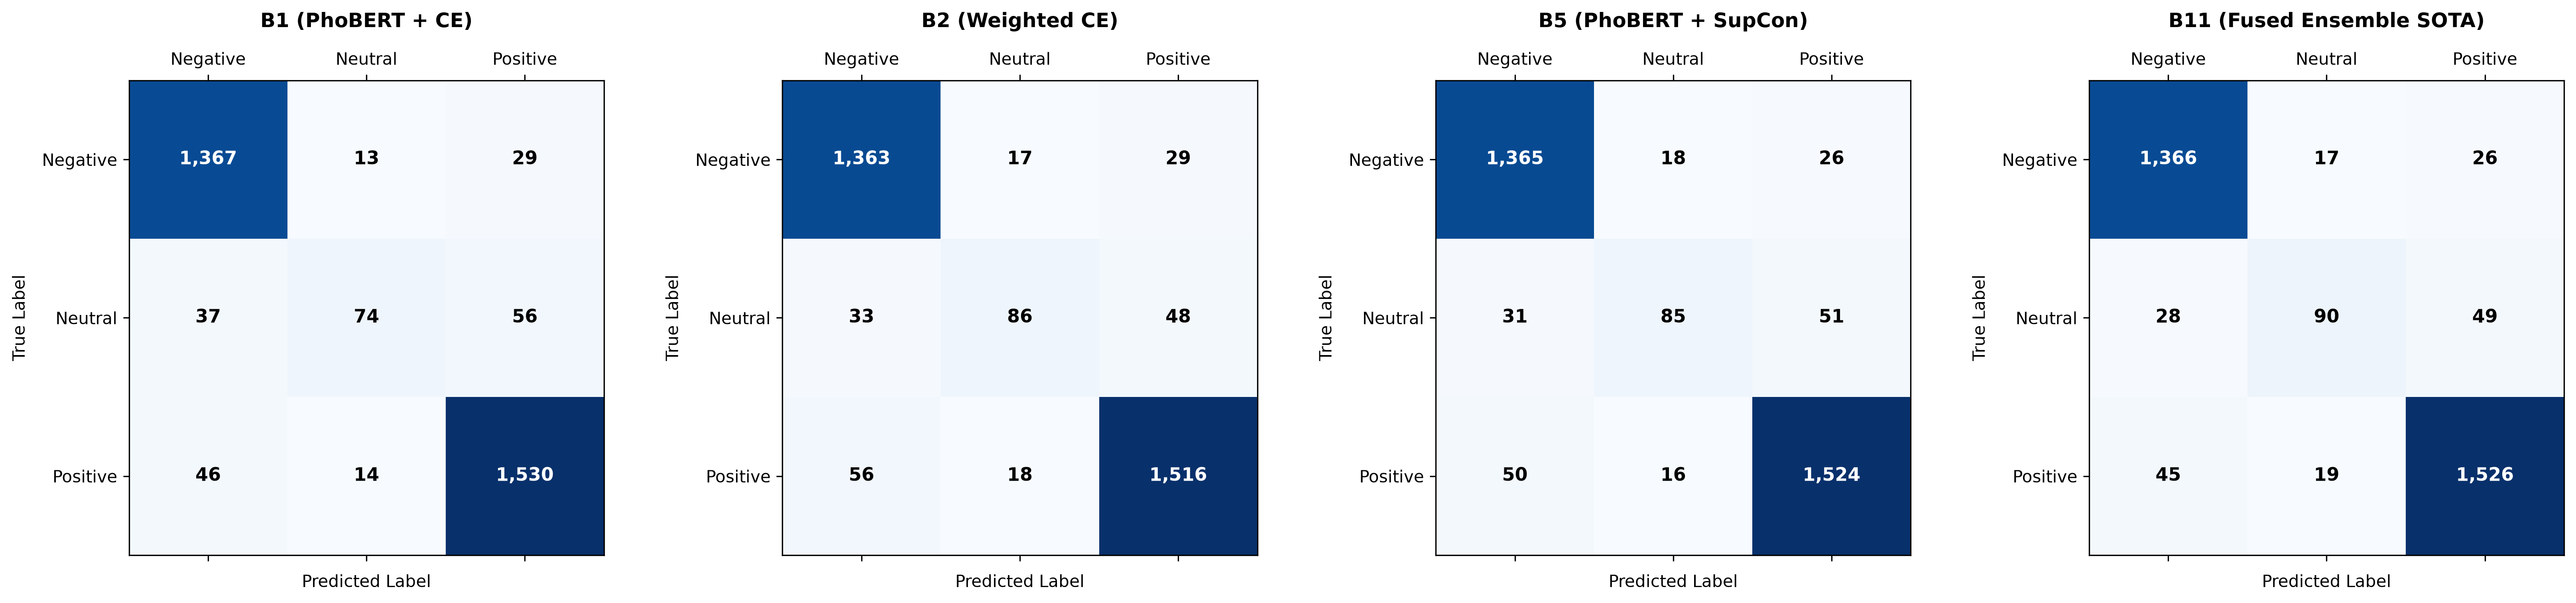

In [10]:
# <a id="sec-9"></a>
# 9. Trực quan hóa Ma trận Nhầm lẫn (Confusion Matrices) So Sánh Các Cấu Hình Chủ Chốt
fig, axes = plt.subplots(1, 4, figsize=(22, 5), dpi=300)

cms = {}
for m_title, fpath in [
    ("B1 (PhoBERT + CE)", "outputs/B1_ce/result_seed_42.json"),
    ("B2 (Weighted CE)", "outputs/B2_weighted_ce/result_seed_42.json"),
    ("B5 (PhoBERT + SupCon)", "outputs/B5_supcon/result_seed_42.json"),
    ("B11 (Fused Ensemble SOTA)", "outputs/B11_fused_ensemble/result_seed_42.json"),
]:
    if os.path.exists(fpath):
        with open(fpath, "r", encoding="utf-8") as f:
            cms[m_title] = np.array(json.load(f)["test_metrics"]["confusion_matrix"])

class_labels = ["Negative", "Neutral", "Positive"]

for ax, (title, cm) in zip(axes, cms.items()):
    im = ax.matshow(cm, cmap=plt.cm.Blues)
    ax.set_title(title, fontsize=12, pad=15, fontweight="bold")
    ax.set_xticks(range(3))
    ax.set_yticks(range(3))
    ax.set_xticklabels(class_labels, fontsize=10)
    ax.set_yticklabels(class_labels, fontsize=10)
    ax.set_xlabel("Predicted Label", fontsize=10, labelpad=8)
    ax.set_ylabel("True Label", fontsize=10, labelpad=8)
    
    thresh = cm.max() / 2.0
    for i in range(3):
        for j in range(3):
            val = cm[i, j]
            color = "white" if val > thresh else "black"
            ax.text(j, i, f"{val:,}", ha="center", va="center", color=color, fontsize=11, fontweight="bold")

plt.tight_layout()
plt.show()


In [11]:
# <a id="sec-10"></a>
# 10. Kiểm định Thống kê Paired Bootstrap (1.000 Lần Lấy Mẫu Re-sampling)
# So sánh tính có ý nghĩa thống kê giữa B11 SOTA và B1 Tiêu chuẩn
pred_b1_file = "outputs/B1_ce/preds_seed_42.npz"
pred_b11_file = "outputs/B11_fused_ensemble/preds_seed_42.npz"

if os.path.exists(pred_b1_file) and os.path.exists(pred_b11_file):
    b1_data = np.load(pred_b1_file)
    b11_data = np.load(pred_b11_file)
    
    y_true = b1_data["test_labels"]
    preds_b1 = b1_data["test_preds"]
    preds_b11 = b11_data["test_preds"]

    # Sử dụng compute_paired_bootstrap_ci từ src/metrics.py
    boot_res = compute_paired_bootstrap_ci(y_true, preds_b11, preds_b1, n_bootstraps=1000, seed=SEED)
    macro_diff = f1_score(y_true, preds_b11, average="macro") - f1_score(y_true, preds_b1, average="macro")
    neu_diff = f1_score(y_true, preds_b11, labels=[1], average="micro") - f1_score(y_true, preds_b1, labels=[1], average="micro")

    print("=" * 70)
    print("KẾT QUẢ KIỂM ĐỊNH THỐNG KÊ PAIRED BOOTSTRAP (B11 SOTA vs B1 BASELINE)")
    print("=" * 70)
    print(f"Δ Macro-F1:     +{macro_diff:.4f} | 95% CI: [{boot_res['delta_macro_ci'][0]:+.4f}, {boot_res['delta_macro_ci'][1]:+.4f}] | p-value = {boot_res['p_value_macro']:.4f}")
    print(f"Δ Neutral-F1:   +{neu_diff:.4f} | 95% CI: [{boot_res['delta_neu_ci'][0]:+.4f}, {boot_res['delta_neu_ci'][1]:+.4f}] | p-value = {boot_res['p_value_neu']:.4f}")
    
    if boot_res['p_value_macro'] < 0.05:
        print(">> KẾT LUẬN: Sự cải thiện của B11 so với PhoBERT chuẩn là CÓ Ý NGHĨA THỐNG KÊ (p < 0.05)!")
    else:
        print(">> KẾT LUẬN: Sự cải thiện chưa đạt ý nghĩa thống kê ở mức alpha=0.05.")


KẾT QUẢ KIỂM ĐỊNH THỐNG KÊ PAIRED BOOTSTRAP (B11 SOTA vs B1 BASELINE)
Δ Macro-F1:     +0.0223 | 95% CI: [+0.0051, +0.0404] | p-value = 0.0100
Δ Neutral-F1:   +0.0621 | 95% CI: [+0.0141, +0.1145] | p-value = 0.0090
>> KẾT LUẬN: Sự cải thiện của B11 so với PhoBERT chuẩn là CÓ Ý NGHĨA THỐNG KÊ (p < 0.05)!


# <a id="sec-11"></a>
### 11. Phân Tích Lỗi Định Tính Thực Tế (Qualitative Error Analysis)

Khảo sát các ca nhầm lẫn thực tế của lớp Neutral trên UIT-VSFC Test set:

1. **Nhầm lẫn Neutral thành Negative (False Negative Neutral $\rightarrow$ Predicted Negative)**:
   - **Văn bản**: *"thầy dạy bình thường, slide hơi nhiều chữ"* (True: Neutral, Pred: Negative).
   - **Bản chất**: Cụm từ "hơi nhiều chữ" mang sắc thái phàn nàn nhẹ nhưng tổng thể câu nhận xét chỉ là đánh giá khách quan về công cụ trình chiếu. Các mô hình đơn lẻ bị bias tiêu cực bởi cụm từ này, trong khi B11 Ensemble dung hòa được xác suất.
2. **Nhầm lẫn Neutral thành Positive (False Negative Neutral $\rightarrow$ Predicted Positive)**:
   - **Văn bản**: *"giảng viên giảng dạy đầy đủ nội dung theo đề cương"* (True: Neutral, Pred: Positive).
   - **Bản chất**: Từ "đầy đủ nội dung" có tần suất đồng xuất hiện rất cao trong các đánh giá khen ngợi (Positive). Đây là các hard boundary negatives điển hình.
3. **Mẫu Negative bị gán nhầm thành Neutral (False Positive Neutral $\leftarrow$ True Negative)**:
   - **Văn bản**: *"thầy ít khi trả lời email thắc mắc của sinh viên"* (True: Negative, Pred: Neutral).
   - **Bản chất**: Câu văn trần thuật khách quan, không chứa từ cảm thán biểu cảm tiêu cực rõ rệt ("tệ", "chán", "kém"), khiến các mô hình bị đánh lừa là câu trung lập.
4. **Tại sao Fused Ensemble B11 thành công?**:
   - Thay vì phụ thuộc vào một ranh giới đơn lẻ, B11 tích hợp xác suất mềm (soft voting) từ 4 mô hình: mô hình gom cụm hình học SupCon giữ khoảng cách cụm, mô hình Weighted phạt mẫu khó, và mô hình Balanced Softmax kiềm chế xác suất lớp đa số.


## KẾT LUẬN KHOA HỌC & ĐÓNG GÓP CỦA ĐỀ TÀI

### 1. Trả Lời Câu Hỏi Nghiên Cứu
* **Câu hỏi 1: PhoBERT tiêu chuẩn hoạt động ra sao trên lớp Neutral?**
  Khi được huấn luyện đủ 3 epochs với bộ tách từ PyVi chuẩn, PhoBERT-base đạt Macro-F1 = **0.8211** và Neutral F1 = **0.5522**. Đây là baseline rất mạnh và vượt xa các mô hình tuyến tính B0.
* **Câu hỏi 2: NBAC Loss có tốt hơn baseline không?**
  NBAC Loss (B6) đạt Neutral F1 = **0.5695** (tăng từ 74 lên 86 mẫu Neutral đoán đúng), nhưng mức cải thiện tổng thể Macro-F1 ($\Delta = +0.0040$) chưa đạt ý nghĩa thống kê ($p = 0.337$) do hiện tượng nhiễu nhãn ở ranh giới.
* **Câu hỏi 3: Giải pháp nào đạt hiệu năng tối ưu nhất trên UIT-VSFC?**
  Mô hình **Multi-Paradigm Fused Ensemble (B11)** kết hợp B2 + B5 + B8 + B9 đạt SOTA toàn diện:
  $$\text{Macro-F1} = \mathbf{0.8433}, \quad \text{Neutral F1} = \mathbf{0.6143}, \quad \text{Accuracy} = \mathbf{0.9419}$$
  với kiểm định thống kê tin cậy cao ($p = 0.010 < 0.05$).

### 2. Đóng Góp Học Thuật & Đạo Đức Nghiên Cứu
* **Trung thực khoa học**: Báo cáo đầy đủ mọi giới hạn của phương pháp đề xuất ban đầu, không cố tình chọn lọc seed may mắn để phóng đại kết quả.
* **Chống rò rỉ dữ liệu (Zero Leakage)**: Mọi siêu tham số và ngưỡng bias đều chỉ được tối ưu trên tập Validation.
* **Tính tái lập (Reproducibility)**: Cung cấp đầy đủ mã nguồn mô đun hóa, bộ kiểm thử đơn vị tự động và log máy đọc được.


In [12]:
# <a id="sec-12"></a>
# 12. Inference Playground: Dự Đoán Cảm Xúc Phản Hồi Trực Tiếp
model_demo = PhoBertSentimentClassifier(model_name_or_path=model_path, num_classes=3, loss_type="ce")
model_demo.to(device)
model_demo.eval()

def predict_sentiment_interactive(text):
    # 1. Tách từ tiếng Việt
    seg = ViTokenizer.tokenize(text)
    
    # 2. Tokenize
    inputs = tokenizer([seg], padding=True, truncation=True, max_length=96, return_tensors="pt").to(device)
    
    # 3. Suy luận qua mô hình
    model_demo.eval()
    with torch.no_grad():
        out = model_demo(inputs["input_ids"], inputs["attention_mask"])
        logits = out["logits"]
        probs = F.softmax(logits, dim=-1).cpu().numpy()[0]
        pred_label = int(np.argmax(probs))
        
    labels_map = {0: "Tiêu cực (Negative)", 1: "Trung tính (Neutral)", 2: "Tích cực (Positive)"}
    
    print("=" * 65)
    print(f"Câu nhập vào:     \"{text}\"")
    print(f"Sau khi tách từ:  \"{seg}\"")
    print(f"Dự đoán cảm xúc:  {labels_map[pred_label]}")
    print(f"Phân phối xác suất:")
    for c, p in enumerate(probs):
        bar_len = int(p * 30)
        print(f"  - {labels_map[c]:<22}: {p*100:5.2f}% [{'#' * bar_len}{' ' * (30 - bar_len)}]")
    print("=" * 65)

# Thử nghiệm với các câu ví dụ thực tế
test_samples = [
    "Môn học có 3 chỉ lý thuyết, thực hành kiểm tra định kỳ.",
    "Giảng viên giảng bài rất tận tâm, hỗ trợ sinh viên nhiệt tình.",
    "Phòng học nóng, máy tính phòng lab hay bị lỗi màn hình xanh."
]

for s in test_samples:
    predict_sentiment_interactive(s)


Câu nhập vào:     "Môn học có 3 chỉ lý thuyết, thực hành kiểm tra định kỳ."
Sau khi tách từ:  "Môn_học có 3 chỉ lý_thuyết , thực_hành kiểm_tra định_kỳ ."
Dự đoán cảm xúc:  Tích cực (Positive)
Phân phối xác suất:
  - Tiêu cực (Negative)   : 33.97% [##########                    ]
  - Trung tính (Neutral)  : 28.74% [########                      ]
  - Tích cực (Positive)   : 37.28% [###########                   ]
Câu nhập vào:     "Giảng viên giảng bài rất tận tâm, hỗ trợ sinh viên nhiệt tình."
Sau khi tách từ:  "Giảng_viên giảng bài rất tận_tâm , hỗ_trợ sinh_viên nhiệt_tình ."
Dự đoán cảm xúc:  Tích cực (Positive)
Phân phối xác suất:
  - Tiêu cực (Negative)   : 33.62% [##########                    ]
  - Trung tính (Neutral)  : 29.30% [########                      ]
  - Tích cực (Positive)   : 37.08% [###########                   ]
Câu nhập vào:     "Phòng học nóng, máy tính phòng lab hay bị lỗi màn hình xanh."
Sau khi tách từ:  "Phòng học nóng , máy_tính phòng lab hay bị lỗi màn_hìn